# Gene Added Value

**Question.** Do the 173 gene mutation counts improve the prediction of relapse-free survival for new patients, beyond age, NPI and PAM50?

**Null hypothesis.** On patients the model has not seen, the genes add nothing.

**Scope.** One fixed model: Structure 3 of the project (log-normal, saved weights fitted on the 1,386 train patients). The 463 test patients are new data for it. "Clinical only" means the same model with each patient's gene effect replaced by its average over the train patients, which is the forecast of a random gene profile. Sections 1 to 4 evaluate the saved model. Section 5 refits Structure 3 and the control Structure 1 (same loss, no genes) with repeated k-fold, and it is the only place where Structure 1 appears.

**Limits.**
- One split with 189 test events: a small gain could go undetected. The repeated k-fold in section 5 addresses this.
- Structure 3 was chosen after looking at the holdout results, so its test numbers are slightly optimistic.

```
S(t | x) = p + (1 - p) S1(t),    z = (log t - mu) / sigma
mu       = z_mu · beta_mu                   linear in age, NPI, PAM50
sigma    = exp(z_sigma · beta_sigma)        linear in PAM50
logit(p) = z_p · beta_p + NN(genes)         linear in age, NPI, PAM50, plus a network on the 173 gene counts
```

`NN(genes)` is called `p_nn`. A positive `p_nn` raises the cure odds and a negative one lowers them.

Sections:

1. Linear effects of the clinical variables.
2. Performance with and without the genes.
3. Permutation of the genes in the test set.
4. The train-test gap.
5. Repeated k-fold against the clinical-only structure.
6. Verdict.

In [1]:
import os, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from IPython.display import display
from tqdm.auto import tqdm

from scipy.stats import norm
from scipy.special import expit, logit
from sklearn.manifold import TSNE
from sklearn.model_selection import RepeatedKFold
import lifelines
from lifelines.utils import concordance_index

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import thetaflow as thf

sys.path.insert(0, "../src")
from package import cure_aft, evaluation_metrics

DIST = "ln"
CACHE_DIR = Path(os.environ.get("DSA_CACHE", "../results/gene_effect"))
CACHE_DIR.mkdir(parents = True, exist_ok = True)
WEIGHTS_DIR = Path(os.environ.get("DSA_WEIGHTS", "../model_weights/Classic Holdout"))

N_SHUFFLES = 1000
N_FOLDS = 5
N_REPEATS = int(os.environ.get("DSA_REPEATS", 5))

SUBTYPES = ["LumA", "LumB", "Her2", "Basal", "claudin-low", "Normal"]
SUBTYPE_COLOR = dict(zip(SUBTYPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
NEG, POS, NS = "#e34948", "#2a78d6", "#b9b8b2"
DIRECTION_COLOR = {"lowers cure odds": NEG, "not significant": NS, "raises cure odds": POS}
DIVERGING = LinearSegmentedColormap.from_list("neg_pos", [NEG, "#e5e4e0", POS])

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.labelsize": 9, "legend.frameon": False,
})

/home/tonso/code/nhilariosilva/metabric_aft_models/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1793895461.364666   75892 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793895462.595229   75892 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Data and model

In [2]:
clean_train = pd.read_csv("../data/00_clean/metabric_train_data.csv")
clean_test = pd.read_csv("../data/00_clean/metabric_test_data.csv")
df_train = pd.read_csv("../data/01_mlready/metabric_train.csv")
df_test = pd.read_csv("../data/01_mlready/metabric_test.csv")
assert (clean_train["patient_id"] == df_train["patient_id"]).all() and (clean_test["patient_id"] == df_test["patient_id"]).all()

def split_data(df, clean):
    z_mu = df.iloc[:, 3:10].copy()
    z_mu.insert(0, "const", 1.0)
    z_sigma = df.iloc[:, 5:10].copy()
    z_sigma.insert(0, "const", 1.0)
    return {
        "y": df["time"] / 12, "delta": df["delta"], "X": df.iloc[:, 10:],
        "z_mu": z_mu, "z_sigma": z_sigma, "z_p": df.iloc[:, 3:10].copy(),
        "subtype": clean["pam50_subtype"].reset_index(drop = True),
    }

TRAIN, TEST = split_data(df_train, clean_train), split_data(df_test, clean_test)
DATA = {"train": TRAIN, "test": TEST}
print(f"train {len(df_train)} patients ({int(TRAIN['delta'].sum())} events), test {len(df_test)} patients ({int(TEST['delta'].sum())} events), {TRAIN['X'].shape[1]} genes")

params, loss, survival_cure = cure_aft.build_cure_aft_structure3(DIST, TRAIN["z_mu"], TRAIN["z_sigma"], TRAIN["z_p"])
NN_ARCH = (cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast)

model = thf.ModelNN(params, loss, *NN_ARCH, input_dim = (TRAIN["X"].shape[1],), seed = 10)
model.load_model(str(WEIGHTS_DIR / "Structure3" / f"{DIST}_model"))

def predict(model, X_train, X_test):
    return survival_cure(model,
                         TRAIN["y"], TRAIN["delta"], X_train, TRAIN["z_mu"], TRAIN["z_sigma"], TRAIN["z_p"],
                         TEST["y"], TEST["delta"], X_test, TEST["z_mu"], TEST["z_sigma"], TEST["z_p"], ngrid = 100)

def gene_effect(model, X):
    out = model.summary(X).iloc[:, -4:].reset_index(drop = True)
    out["significant"] = (out["p_nn_lower"] > 0) | (out["p_nn_upper"] < 0)
    out["direction"] = np.where(~out["significant"], "not significant", np.where(out["p_nn"] > 0, "raises cure odds", "lowers cure odds"))
    return out

def survival_at(summary, split, t):
    grid, S = summary["ts_grid"].ravel(), summary[f"S_ts_{split}"]
    return np.array([np.interp(t, grid, S[:, j]) for j in range(S.shape[1])])

def with_gene_part(with_pred, p):
    """Forecast with the cure probability replaced by p (dict split -> array) and the timing part S1 of the model kept.
    The survival function S = p + (1 - p) S1 is linear in p."""
    out = dict(with_pred)
    for split, p_new in p.items():
        p_old = with_pred[f"p_{split}"]
        for key in (f"S_ts_{split}", f"S_{split}"):
            out[key] = p_new + (1 - p_new) * (with_pred[key] - p_old) / (1 - p_old)
        out[f"p_{split}"] = p_new
        out[f"H_{split}"] = -np.log(np.clip(out[f"S_{split}"], 1e-15, 1))
    return out

WITH = predict(model, TRAIN["X"], TEST["X"])
GENE = {s: gene_effect(model, DATA[s]["X"]) for s in DATA}
CLINICAL = {s: (DATA[s]["z_p"].to_numpy() @ model.predict("p_beta")[:, None]).ravel() for s in DATA}
P_AVERAGE = {s: expit(CLINICAL[s][:, None] + GENE["train"]["p_nn"].to_numpy()).mean(axis = 1) for s in DATA}
WITHOUT = with_gene_part(WITH, P_AVERAGE)
for s in DATA:
    print(f"{s}: {GENE[s]['significant'].mean():.1%} of patients have a gene effect whose 95% interval excludes 0")

train 1386 patients (565 events), test 463 patients (189 events), 173 genes
Model successfully loaded from ../model_weights/Classic Holdout/Structure3/ln_model.


train: 48.1% of patients have a gene effect whose 95% interval excludes 0
test: 44.3% of patients have a gene effect whose 95% interval excludes 0


## 1. Linear effects of the clinical variables

Time ratios for `mu` (above 1 means later relapse among the susceptible), ratios for `sigma` (above 1 means more spread-out relapse times) and odds ratios for the cure fraction `p` (above 1 means higher cure odds). Intervals are Wald 95% intervals from the covariance thetaflow computes at the optimum. Filled points have an interval that excludes 1. The cure effects are adjusted for the gene effect `p_nn`. The reference subtype is LumA.

/home/tonso/code/nhilariosilva/metabric_aft_models/venv/lib/python3.12/site-packages/thetaflow/modelnn.py:2871: UserWarning: Model supports both neural network modeled parameters and independent parameters.
As a list of input values, x, was not provided, obtaining the covariances only for ['mu_beta', 'sigma_beta', 'p_beta'].
  warnings.warn(


,Coef,Se,pvalue,lower,upper
mu_const,2.308,0.175,0.000,1.966,2.651
mu_age_at_diagnosis,0.031,0.060,0.607,-0.087,0.149
mu_npi,-0.149,0.060,0.013,-0.267,-0.031
mu_pam50_subtype_Basal,-1.479,0.276,0.000,-2.020,-0.937
mu_pam50_subtype_Her2,-1.158,0.206,0.000,-1.562,-0.754
mu_pam50_subtype_LumB,-0.743,0.208,0.000,-1.150,-0.336
mu_pam50_subtype_Normal,-0.283,0.344,0.411,-0.957,0.392
mu_pam50_subtype_claudin-low,-0.282,0.506,0.578,-1.274,0.711
sigma_const,0.225,0.080,0.005,0.068,0.382
sigma_pam50_subtype_Basal,-0.060,0.173,0.728,-0.399,0.279


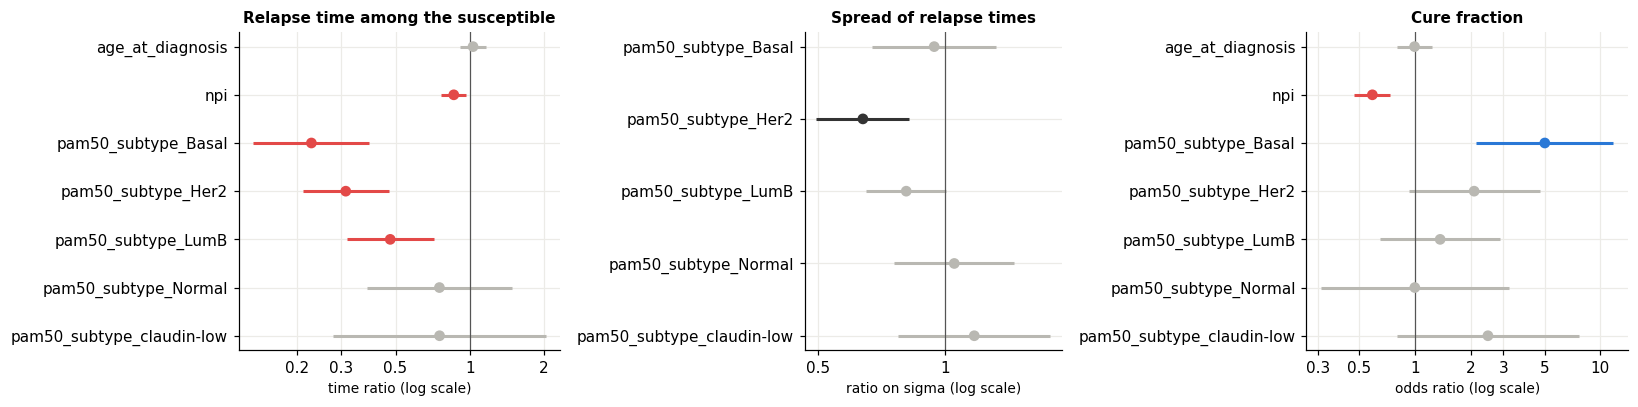

In [3]:
colnames = [f"mu_{c}" for c in TRAIN["z_mu"].columns] + [f"sigma_{c}" for c in TRAIN["z_sigma"].columns] + [f"p_{c}" for c in TRAIN["z_p"].columns]
betas = cure_aft.summary_betas(model, colnames)
z = norm.ppf(0.975)
betas["lower"], betas["upper"] = betas["Coef"] - z * betas["Se"], betas["Coef"] + z * betas["Se"]
display(betas[["Coef", "Se", "pvalue", "lower", "upper"]].round(3))

def forest(ax, prefix, title, xlabel, signed = True):
    b = betas[betas.index.str.startswith(prefix + "_") & (betas.index != prefix + "_const")]
    y = np.arange(len(b))[::-1]
    sig = (b["lower"] > 0) | (b["upper"] < 0)
    colors = np.where(~sig, NS, np.where(b["Coef"] > 0, POS, NEG)) if signed else np.where(sig, "#333333", NS)
    ax.hlines(y, np.exp(b["lower"]), np.exp(b["upper"]), color = colors, lw = 2)
    ax.scatter(np.exp(b["Coef"]), y, c = colors, s = 36, zorder = 3)
    ax.axvline(1, color = "#555555", lw = 0.8)
    ax.set_xscale("log")
    ticks = [t for t in (0.1, 0.2, 0.3, 0.5, 1, 2, 3, 5, 10) if ax.get_xlim()[0] <= t <= ax.get_xlim()[1]]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.minorticks_off()
    ax.set_yticks(y, [n[len(prefix) + 1:] for n in b.index])
    ax.set_title(title)
    ax.set_xlabel(xlabel)

fig, ax = plt.subplots(1, 3, figsize = (15, 3.8), gridspec_kw = {"width_ratios": [1, 0.8, 1]})
forest(ax[0], "mu", "Relapse time among the susceptible", "time ratio (log scale)")
forest(ax[1], "sigma", "Spread of relapse times", "ratio on sigma (log scale)", signed = False)
forest(ax[2], "p", "Cure fraction", "odds ratio (log scale)")
fig.tight_layout()
plt.show()

## 2. Performance with and without the genes

"Without the genes" means the same fitted model with each patient's `p_nn` replaced by its average over the train patients. This equals the cure probability averaged over every possible shuffle of the genes across patients. It keeps the baseline cure level the model learned and removes the link between a patient's genes and that patient's own outcome.

Every row is evaluated on the train and on the test patients with the same fixed weights. C-index (of the 10-year relapse-free probability) and log-likelihood: higher is better. IBS (integrated IPCW Brier score) and AD (Anderson-Darling statistic of the residuals, normalized by the sample size): lower is better. The gene part alone is the ranking given by `p_nn` only, so it has a C-index and no other metric. The gain is the clinical + genes row minus the clinical only row.

In [4]:
def loss_data(z_mu, z_sigma, z_p, y, delta):
    return (None, *(tf.cast(z, tf.float32) for z in (z_mu, z_sigma, z_p)), tf.cast(y, tf.float32)[:, None], tf.cast(delta, tf.float32)[:, None])

LOSS_DATA = {s: loss_data(*(DATA[s][k] for k in ("z_mu", "z_sigma", "z_p", "y", "delta"))) for s in DATA}
S1_AT_10 = {s: survival_at(with_gene_part(WITH, {k: np.zeros(len(DATA[k]["y"])) for k in DATA}), s, 10) for s in DATA}

# a "gene part" g is the term added to the cure logit by the genes: with the genes it is p_nn, without them it gives the average cure probability
G_WITH = {s: GENE[s]["p_nn"].to_numpy() for s in DATA}
G_WITHOUT = {s: logit(P_AVERAGE[s]) - CLINICAL[s] for s in DATA}

def probability(g, split):
    return expit(CLINICAL[split] + g)

def loglik(g, split):
    return -float(loss(model, tf.cast(g, tf.float32)[:, None], LOSS_DATA[split])) / len(g)

def cindex(g, split):
    p = probability(g, split)
    return concordance_index(DATA[split]["y"], p + (1 - p) * S1_AT_10[split], DATA[split]["delta"])

def metrics(G, split):
    pred = with_gene_part(WITH, {s: probability(G[s], s) for s in DATA})
    r = {**pred, **{f"{k}_test": pred[f"{k}_{split}"] for k in ("y", "delta", "S_ts", "S")}}
    return {"C-index": cindex(G[split], split), "log-lik": loglik(G[split], split),
            "IBS": evaluation_metrics.calculate_integrated_ipcw_brier_score(r),
            "AD": evaluation_metrics.calculate_ad_statistic_avg(r)}

def metrics_table(split):
    t = pd.DataFrame({"Clinical only": metrics(G_WITHOUT, split), "Clinical + genes": metrics(G_WITH, split)}).T
    t.loc["Gain (with minus without)"] = t.loc["Clinical + genes"] - t.loc["Clinical only"]
    t.loc["Gene part alone"] = [concordance_index(DATA[split]["y"], G_WITH[split], DATA[split]["delta"]), np.nan, np.nan, np.nan]
    return t

TABLE = pd.concat({s: metrics_table(s) for s in DATA}, axis = 1)
display(TABLE.round(3))

/home/tonso/code/nhilariosilva/metabric_aft_models/notebooks/../src/package/evaluation_metrics.py:66: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  model_ad = anderson(resid_model_test).statistic / len(results_dict["S_test"])
/home/tonso/code/nhilariosilva/metabric_aft_models/notebooks/../src/package/evaluation_metrics.py:66: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing t

train                        test                 \
                          C-index log-lik    IBS   AD C-index log-lik    IBS   
Clinical only               0.641  -1.585  0.208  0.0   0.621  -1.611  0.197   
Clinical + genes            0.698  -1.533  0.210  0.0   0.567  -1.731  0.220   
Gain (with minus without)   0.057   0.051  0.002  0.0  -0.053  -0.120  0.023   
Gene part alone             0.652     NaN    NaN  NaN   0.500     NaN    NaN   

                                  
                              AD  
Clinical only              0.001  
Clinical + genes           0.001  
Gain (with minus without) -0.000  
Gene part alone              NaN

## 3. Permutation of the genes in the test set

H0: given the clinical variables, the genes carry no information about survival. The network scores each patient from that patient's genes alone, so shuffling the gene rows across patients is the same as shuffling the gene part `g` across patients. Each shuffle gives every patient another patient's gene effect, keeps the clinical variables and the outcomes in place and recomputes the statistic with the fixed weights, without refitting. The p-value is the share of shuffles (counting the real arrangement) with a value at least as high as the real one, so a small p means that the genes help.

  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:05<00:05,  5.57s/it]

100%|██████████| 2/2 [00:08<00:00,  3.78s/it]

100%|██████████| 2/2 [00:08<00:00,  4.05s/it]

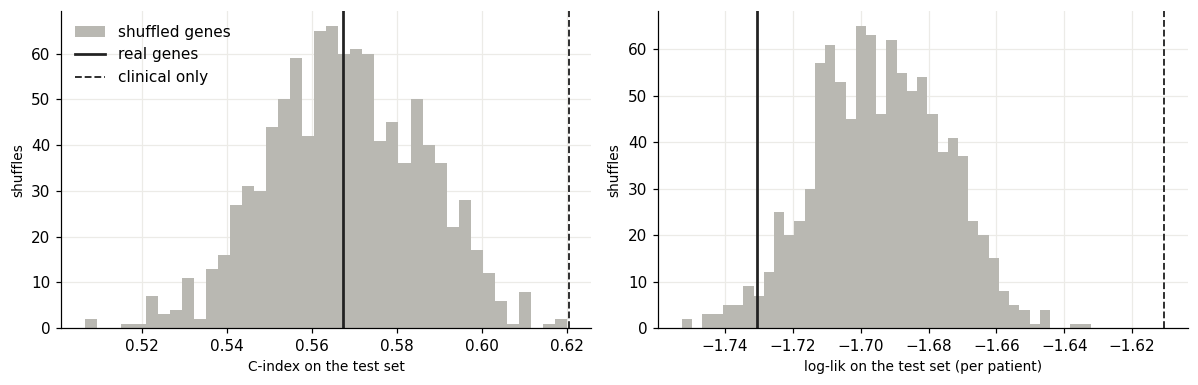

train C-index  real 0.6981 | shuffled mean 0.5868, 95th pct 0.6036 | p = 0.001
train log-lik  real -1.5331 | shuffled mean -1.6544, 95th pct -1.6377 | p = 0.001
test  C-index  real 0.5675 | shuffled mean 0.5679, 95th pct 0.5969 | p = 0.500
test  log-lik  real -1.7305 | shuffled mean -1.6943, 95th pct -1.6642 | p = 0.972


In [5]:
rng = np.random.default_rng(0)
METRICS = ("C-index", "log-lik")
REAL = {s: {"C-index": cindex(G_WITH[s], s), "log-lik": loglik(G_WITH[s], s)} for s in DATA}
WITHOUT_REF = {s: {"C-index": cindex(G_WITHOUT[s], s), "log-lik": loglik(G_WITHOUT[s], s)} for s in DATA}
NULL = {s: pd.DataFrame([{"C-index": cindex(g, s), "log-lik": loglik(g, s)}
                         for g in (rng.permutation(G_WITH[s]) for _ in range(N_SHUFFLES))]) for s in tqdm(DATA)}

fig, ax = plt.subplots(1, 2, figsize = (11, 3.6))
for a, m in zip(ax, METRICS):
    a.hist(NULL["test"][m], bins = 40, color = NS, label = "shuffled genes")
    a.axvline(REAL["test"][m], color = "#222222", lw = 1.8, label = "real genes")
    a.axvline(WITHOUT_REF["test"][m], color = "#222222", lw = 1.2, ls = "--", label = "clinical only")
    a.set_xlabel(f"{m} on the test set" + (" (per patient)" if m == "log-lik" else ""))
    a.set_ylabel("shuffles")
ax[0].legend()
fig.tight_layout()
plt.show()

for s in DATA:
    for m in METRICS:
        p = (1 + (NULL[s][m] >= REAL[s][m]).sum()) / (N_SHUFFLES + 1)
        print(f"{s:5s} {m:8s} real {REAL[s][m]:.4f} | shuffled mean {NULL[s][m].mean():.4f}, 95th pct {NULL[s][m].quantile(0.95):.4f} | p = {p:.3f}")

## 4. The train-test gap

The gain is the clinical + genes value minus the clinical only value, for the real genes (dot) and for the shuffled genes (gray bar: 95% of the shuffles). A dot above the bar means that the genes helped beyond what a random arrangement of the same gene effects gives. The Kaplan-Meier curves below split the patients by the sign of the gene effect (interval excluding 0). If the gene effect carried signal, the groups would separate on the test set as they do on the train set.

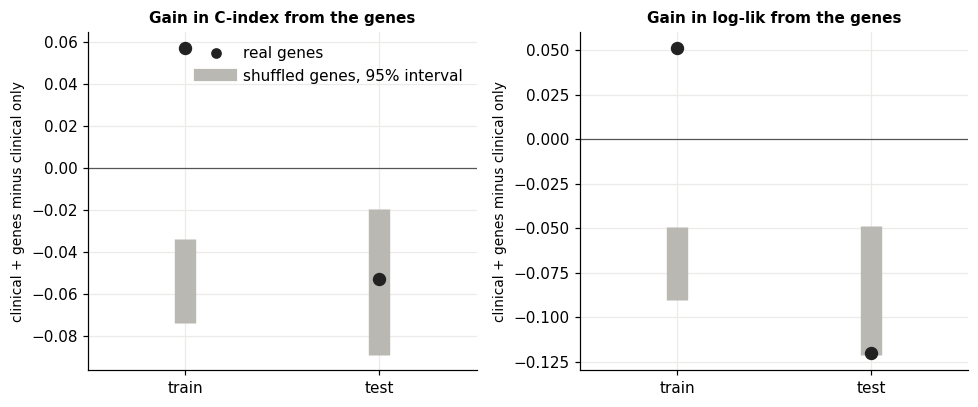

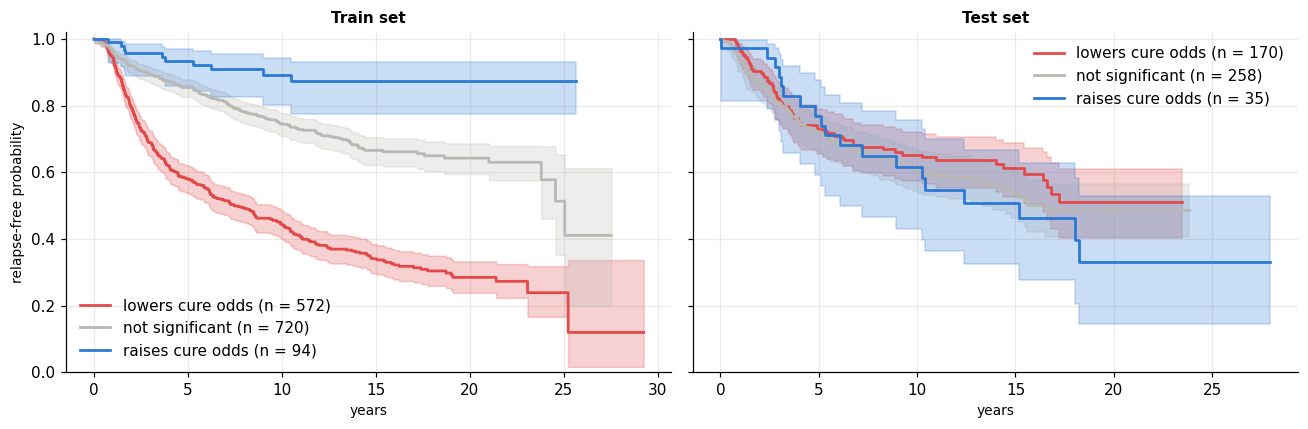

In [6]:
fig, ax = plt.subplots(1, 2, figsize = (9, 3.8))
for a, m in zip(ax, METRICS):
    for x, s in enumerate(DATA):
        lo, hi = np.quantile(NULL[s][m] - WITHOUT_REF[s][m], [0.025, 0.975])
        a.vlines(x, lo, hi, color = NS, lw = 14)
        a.scatter(x, REAL[s][m] - WITHOUT_REF[s][m], color = "#222222", s = 60, zorder = 3)
    a.axhline(0, color = "#555555", lw = 0.8)
    a.set_xticks([0, 1], list(DATA))
    a.set_xlim(-0.5, 1.5)
    a.set_title(f"Gain in {m} from the genes")
    a.set_ylabel("clinical + genes minus clinical only")
ax[0].legend(handles = [Line2D([], [], marker = "o", ls = "", color = "#222222", label = "real genes"),
                        Line2D([], [], color = NS, lw = 8, label = "shuffled genes, 95% interval")], loc = "upper right")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize = (12, 4), sharey = True)
for a, s in zip(ax, DATA):
    d, direction = DATA[s], GENE[s]["direction"]
    for k, color in DIRECTION_COLOR.items():
        mask = (direction == k).to_numpy()
        lifelines.KaplanMeierFitter().fit(d["y"][mask], d["delta"][mask], label = f"{k} (n = {mask.sum()})").plot_survival_function(ax = a, color = color, ci_show = True, lw = 1.8)
    a.set_title(f"{s.capitalize()} set")
    a.set_xlabel("years")
    a.set_ylim(0, 1.02)
ax[0].set_ylabel("relapse-free probability")
fig.tight_layout()
plt.show()

## 5. Repeated k-fold against the clinical-only structure

The fixed-weight tests above use one split. Here all 1,849 patients enter a 5-fold cross-validation repeated 5 times. In every fold, Structure 3 (with the network) and Structure 1 (same loss, same clinical variables, no genes, a constant in the cure part) are refitted with the project's `train_model` on the training folds and scored on the held-out fold. The gain is Structure 3 minus Structure 1. The folds share patients, so the spread across folds describes the variation without a formal p-value. Every fit is cached.

  0%|          | 0/25 [00:00<?, ?it/s]

100%|██████████| 25/25 [00:00<00:00, 1619.07it/s]

c_index          loglik        
             mean     std    mean     std
structure                                
1          0.6402  0.0179 -1.5935  0.0675
3          0.6316  0.0201 -1.6144  0.0760

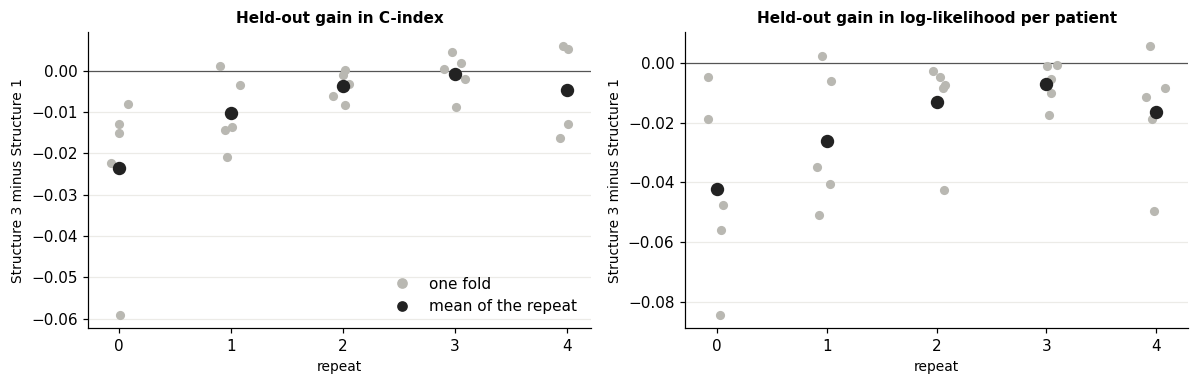

c_index  gain: mean -0.0086, SD over folds 0.0132, positive in 28% of the 25 folds
loglik   gain: mean -0.0209, SD over folds 0.0231, positive in 8% of the 25 folds


In [7]:
ALL = {k: pd.concat([TRAIN[k], TEST[k]], ignore_index = True) for k in ("y", "delta", "X", "z_mu", "z_sigma", "z_p")}
ALL["z_p1"] = ALL["z_p"].copy()
ALL["z_p1"].insert(0, "const", 1.0)
params1, loss1, survival_cure1 = cure_aft.build_cure_aft_structure1(DIST, ALL["z_mu"], ALL["z_sigma"], ALL["z_p1"])

def part(key, idx):
    return ALL[key].iloc[idx].reset_index(drop = True)

def fit_evaluate(structure, tr, te):
    z_p = "z_p" if structure == 3 else "z_p1"
    fit, held = ([part(k, i) for k in ("z_mu", "z_sigma", z_p, "y", "delta")] for i in (tr, te))
    z_fit, (y_fit, d_fit), z_held, (y_held, d_held) = fit[:3], fit[3:], held[:3], held[3:]
    if structure == 3:
        X_fit, X_held = part("X", tr), part("X", te)
        m = cure_aft.train_model(params, loss, *NN_ARCH, X_fit, fit, verbose = False)
        summary = survival_cure(m, y_fit, d_fit, X_fit, *z_fit, y_held, d_held, X_held, *z_held)
        nn_output, loss_fn = m.neural_network_call(m, tf.cast(X_held, tf.float32), training = False), loss
    else:
        m = cure_aft.train_model(params1, loss1, None, None, None, None, fit, verbose = False)
        summary = survival_cure1(m, y_fit, d_fit, *z_fit, y_held, d_held, *z_held)
        nn_output, loss_fn = None, loss1
    return {"c_index": concordance_index(y_held, survival_at(summary, "test", 10), d_held),
            "loglik": -float(loss_fn(m, nn_output, loss_data(*held))) / len(te)}

folds = list(RepeatedKFold(n_splits = N_FOLDS, n_repeats = N_REPEATS, random_state = 0).split(ALL["X"]))
cv = []
for k, (tr, te) in enumerate(tqdm(folds)):
    for structure in (3, 1):
        path = CACHE_DIR / f"cv{k}_s{structure}.json"
        if not path.exists():
            path.write_text(json.dumps(fit_evaluate(structure, tr, te)))
        cv.append({"repeat": k // N_FOLDS, "fold": k % N_FOLDS, "structure": structure, **json.loads(path.read_text())})
cv = pd.DataFrame(cv)

wide = cv.pivot(index = ["repeat", "fold"], columns = "structure", values = ["c_index", "loglik"])
CV_GAIN = pd.DataFrame({m: wide[m][3] - wide[m][1] for m in ("c_index", "loglik")}).reset_index()

display(cv.groupby("structure")[["c_index", "loglik"]].agg(["mean", "std"]).round(4))

fig, ax = plt.subplots(1, 2, figsize = (11, 3.6))
for a, (m, title) in zip(ax, [("c_index", "C-index"), ("loglik", "log-likelihood per patient")]):
    sns.stripplot(data = CV_GAIN, x = "repeat", y = m, color = NS, size = 6, ax = a)
    a.scatter(range(N_REPEATS), CV_GAIN.groupby("repeat")[m].mean(), color = "#222222", s = 60, zorder = 3)
    a.axhline(0, color = "#555555", lw = 0.8)
    a.set_xlabel("repeat")
    a.set_ylabel("Structure 3 minus Structure 1")
    a.set_title(f"Held-out gain in {title}")
ax[0].legend(handles = [Line2D([], [], marker = "o", ls = "", color = NS, label = "one fold"),
                        Line2D([], [], marker = "o", ls = "", color = "#222222", label = "mean of the repeat")], loc = "best")
fig.tight_layout()
plt.show()

for m in ("c_index", "loglik"):
    print(f"{m:8s} gain: mean {CV_GAIN[m].mean():+.4f}, SD over folds {CV_GAIN[m].std():.4f}, positive in {(CV_GAIN[m] > 0).mean():.0%} of the {len(CV_GAIN)} folds")

## 6. Verdict

In [8]:
for s in DATA:
    for m in METRICS:
        gain = REAL[s][m] - WITHOUT_REF[s][m]
        shuffled = NULL[s][m].mean() - WITHOUT_REF[s][m]
        p = (1 + (NULL[s][m] >= REAL[s][m]).sum()) / (N_SHUFFLES + 1)
        print(f"{s:5s} {m:8s} gain from the real genes {gain:+.4f} | gain from shuffled genes {shuffled:+.4f} | p = {p:.3f}")
print(f"Repeated {N_FOLDS}-fold, {N_REPEATS} repeats, Structure 3 minus Structure 1: "
      f"C-index {CV_GAIN['c_index'].mean():+.4f} (positive in {(CV_GAIN['c_index'] > 0).mean():.0%} of folds), "
      f"log-likelihood {CV_GAIN['loglik'].mean():+.4f} per patient (positive in {(CV_GAIN['loglik'] > 0).mean():.0%} of folds)")

train C-index  gain from the real genes +0.0574 | gain from shuffled genes -0.0539 | p = 0.001
train log-lik  gain from the real genes +0.0515 | gain from shuffled genes -0.0698 | p = 0.001
test  C-index  gain from the real genes -0.0531 | gain from shuffled genes -0.0527 | p = 0.500
test  log-lik  gain from the real genes -0.1199 | gain from shuffled genes -0.0837 | p = 0.972
Repeated 5-fold, 5 repeats, Structure 3 minus Structure 1: C-index -0.0086 (positive in 28% of folds), log-likelihood -0.0209 per patient (positive in 8% of folds)
